# 06 · Data augmentation

Create deterministic gain-and-noise variants for training recordings only.

Run notebooks **01 → 09** in order. This notebook contains its implementation directly; it does not import project code from `src/`.

In [1]:
from pathlib import Path
import json
import hashlib
import wave
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root / "configs/preprocessing.json").read_text())
out = root / "data/processed" / cfg["run_name"]
reports = root / "reports/preprocessing" / cfg["run_name"]
out.mkdir(parents=True, exist_ok=True)
reports.mkdir(parents=True, exist_ok=True)

In [2]:
def load_manifest(name):
    path = out / name
    if not path.exists():
        raise FileNotFoundError(f"Run the preceding notebook first: {path}")
    return [json.loads(line) for line in path.read_text().splitlines()]

def save_manifest(name, rows):
    path = out / name
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w") as stream:
        for row in rows:
            stream.write(json.dumps(row, allow_nan=False) + "\n")

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

### Math for the next code block — PCM round trip

The reader maps integer PCM to full scale with $x=q/32768$. The writer maps back with

$$q=\operatorname{clip}(\operatorname{round}(32768x),-32768,32767).$$

In [3]:
def read_audio(path):
    with wave.open(str(path), "rb") as wav:
        meta = {"sample_rate": wav.getframerate(), "channels": wav.getnchannels(),
                "sample_width": wav.getsampwidth(), "frames": wav.getnframes()}
        if wav.getcomptype() != "NONE" or meta["sample_width"] != 2:
            raise ValueError("Only uncompressed PCM16 WAV is supported")
        pcm = wav.readframes(meta["frames"])
    if not meta["frames"] or len(pcm) != meta["frames"] * meta["channels"] * 2:
        raise ValueError("Empty or truncated PCM")
    audio = np.frombuffer(pcm, dtype="<i2").reshape(-1, meta["channels"]).astype(np.float32) / 32768
    meta["pcm_sha256"] = hashlib.sha256(pcm).hexdigest()
    return audio, meta

def write_audio(path, audio, rate):
    path.parent.mkdir(parents=True, exist_ok=True)
    pcm = np.clip(np.rint(np.asarray(audio) * 32768), -32768, 32767).astype("<i2")
    with wave.open(str(path), "wb") as wav:
        wav.setnchannels(1); wav.setsampwidth(2); wav.setframerate(rate)
        wav.writeframes(pcm.tobytes())

## Reproducible waveform augmentation

Whole-clip RMS defines SNR because verified speech boundaries are unavailable. Anti-clipping scale is recorded.

### Math for the next code block — reproducible randomness

Each variant receives a deterministic integer seed

$$z_i=\operatorname{int}(\operatorname{SHA256}(k\Vert i)_{0:64}).$$

The same experiment seed $k$ and variant ID $i$ reproduce the same gain and noise realization.

In [4]:
def seed_for(item):
    return int(hashlib.sha256(f"{cfg['seed']}:{item}".encode()).hexdigest()[:16],16)

### Math for the next code block — gain, target SNR, and clipping protection

Draw gain $G$ dB and SNR $S$ dB from their configured ranges. Apply gain:

$$x_g[n]=x[n]10^{G/20}.$$

For unit Gaussian noise $v[n]$, choose

$$\alpha=\frac{\operatorname{RMS}(x_g)}{10^{S/20}\max(\operatorname{RMS}(v),10^{-12})},\qquad
u[n]=x_g[n]+\alpha v[n].$$

This makes $20\log_{10}(\operatorname{RMS}(x_g)/\operatorname{RMS}(\alpha v))=S$. Finally,

$$c=\min\!\left(1,\frac{0.99}{\max(\max_n|u[n]|,10^{-12})}\right),\qquad y[n]=cu[n].$$

$c$ prevents clipping. SNR is measured over the whole clip because speech boundaries are missing.

In [5]:
def augment_signal(
        signal,
        seed
):

    # RNG
    rng=np.random.default_rng(seed)
    settings=cfg["augmentation"]

    # Gain db
    gain_db=float(rng.uniform(*settings["gain_db"]))
    
    # SNR db
    snr_db=float(rng.uniform(*settings["synthetic_noise_snr_db"]))

    # Gained
    gained=signal.astype(np.float64)*10**(gain_db/20)

    # Noise
    noise=rng.normal(size=len(signal))
    noise*=np.sqrt(np.mean(gained**2))/(10**(snr_db/20)*max(np.sqrt(np.mean(noise**2)),1e-12))
    mixed=gained+noise

    # Scale
    scale=min(1.,.99/max(float(np.max(np.abs(mixed))),1e-12))
    
    return (mixed*scale).astype(np.float32),{
        "gain_db":gain_db,
        "whole_clip_snr_db":snr_db,
        "anti_clip_scale":scale,
        "noise_type":"synthetic_white"
    }

In [6]:
originals=load_manifest("05_standardized.jsonl")
rows=list(originals)
for record in originals:
    if record["split"]!="train": continue
    signal,_=read_audio(root/record["audio_path"])
    for index in range(cfg["augmentation"]["copies_per_training_clip"]):
        identifier=f"{record['id']}__aug{index}"; variant,parameters=augment_signal(signal[:,0],seed_for(identifier))
        path=out/"06_augmented"/"train"/f"{identifier}.wav"; write_audio(path,variant,cfg["sample_rate"])
        rows.append({**record,"id":identifier,"parent_id":record["id"],"is_augmented":True,
                     "audio_path":str(path.relative_to(root)),"augmentation":parameters})
save_manifest("06_augmented.jsonl",rows)

In [7]:
display({"originals":len(originals),"training_variants":sum(r["is_augmented"] for r in rows),
         "validation_variants":sum(r["is_augmented"] and r["split"]=="validation" for r in rows),
         "test_variants":sum(r["is_augmented"] and r["split"]=="test" for r in rows)})

{'originals': 7973,
 'training_variants': 6357,
 'validation_variants': 0,
 'test_variants': 0}

## Compare one parent and variant

In [8]:
INK, MUTED, BLUE, TEAL, AMBER, RED = "#152b42", "#586c7d", "#3265bb", "#087f8c", "#ba6b10", "#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb", "axes.facecolor":"white",
                     "axes.edgecolor":"#c8d5e2", "axes.labelcolor":INK,
                     "xtick.color":MUTED, "ytick.color":MUTED, "font.size":11})

def finish_figure(fig, name):
    directory = reports / "figures"
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f"{name}.png", dpi=170, bbox_inches="tight")
    fig.savefig(directory / f"{name}.svg", bbox_inches="tight")
    plt.show()

### Math for the next code block — comparison axis

Both waveforms use $t_n=n/f_s$. Augmentation preserves the number of samples, so parent and variant have identical time axes and duration.

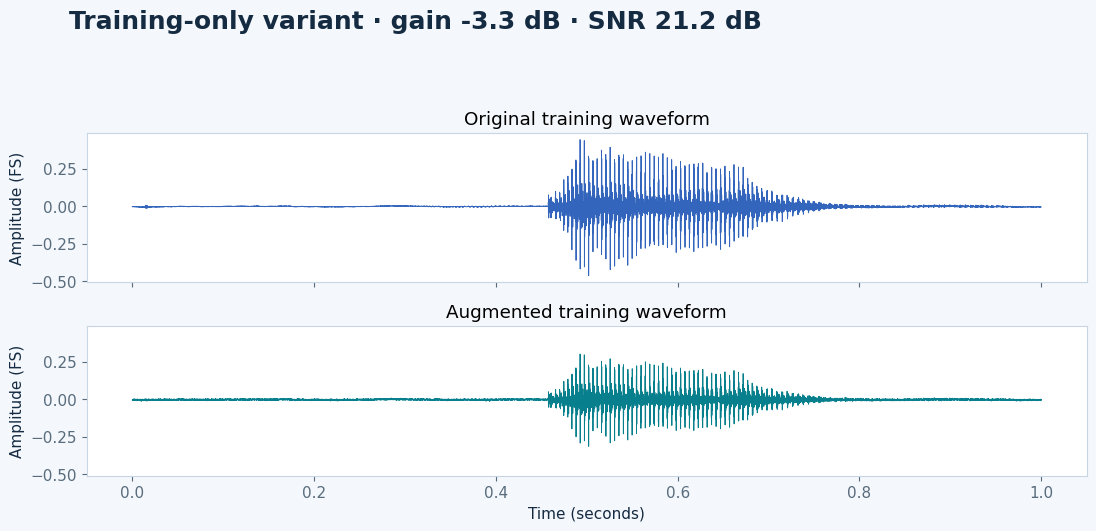

In [9]:
variant=next(r for r in rows if r["is_augmented"]); parent=next(r for r in originals if r["id"]==variant["parent_id"])
a,_=read_audio(root/parent["audio_path"]); b,_=read_audio(root/variant["audio_path"])
fig,axes=plt.subplots(2,1,figsize=(11,5.5),sharex=True,sharey=True)
for ax,signal,title,color in zip(axes,[a[:,0],b[:,0]],["Original training waveform","Augmented training waveform"],[BLUE,TEAL]):
    ax.plot(np.arange(len(signal))/cfg["sample_rate"],signal,lw=.65,color=color); ax.set(title=title,ylabel="Amplitude (FS)")
axes[-1].set_xlabel("Time (seconds)"); p=variant["augmentation"]
fig.suptitle(f"Training-only variant · gain {p['gain_db']:+.1f} dB · SNR {p['whole_clip_snr_db']:.1f} dB",x=.06,ha="left",fontsize=18,weight="bold",color=INK)
fig.tight_layout(rect=(0,.02,1,.9)); finish_figure(fig,"06_augmentation")

Continue with [07 · Feature extraction](07_feature_extraction.ipynb).